# Dự báo visitors tại bốn điểm đến di tích Huế

**Mô hình:** Seasonal Naive-7, ARX–Ridge, LSTM, GRU, 1D-CNN, Transformer và validation-weighted ensemble.  
**Horizon:** 1, 7 và 14 ngày.  
**Nguyên tắc:** chia tuần tự; không shuffle; scaler chỉ fit trên train; test không dùng để chọn mô hình/siêu tham số; đánh giá trên đơn vị visitors thực.

Notebook tải bốn CSV trực tiếp từ thư mục Google Drive đã chia sẻ và lưu toàn bộ kết quả vào:

`/content/drive/MyDrive/NCS/Tourist/2-results`

> `FAST_MODE=True` dùng để kiểm tra luồng chạy. Khi lấy kết quả cho bài báo, giữ `FAST_MODE=False`, `RUN_OPTUNA=True` và chạy GPU.


## 1. Cài đặt thư viện


In [1]:
!pip -q install "gdown>=5.2" "holidays>=0.53" "optuna>=3.6" "openpyxl>=3.1"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 28.5 MB/s eta 0:00:00


## 2. Import, cấu hình và tái lập

- ARX–Ridge là mô hình tuyến tính chính, sử dụng đúng cùng tập thông tin nhân quả với các mô hình học sâu.
- Seasonal Naive-7 là benchmark tối thiểu.
- Bốn mô hình học sâu dùng chung thiết kế multivariate: lịch sử của cả bốn điểm đến và lịch tương lai đã biết.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, gc, json, math, time, random, hashlib, platform, warnings, subprocess
from pathlib import Path
from datetime import datetime
from importlib import metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.optimize import minimize
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

import holidays
import gdown
import optuna
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

# ---------------- CẤU HÌNH TRUNG TÂM ----------------
SEED = 2026
FAST_MODE = False          # True: chạy kiểm tra nhanh; False: chạy bài báo
RUN_OPTUNA = True
APPLY_CONFIRMED_CLOSURE_OVERRIDE = True

HORIZONS = [1, 7, 14]
MAX_HORIZON = max(HORIZONS)
LOOKBACK_CANDIDATES = [28, 56] if FAST_MODE else [28, 56, 84, 112]
N_TRIALS = 2 if FAST_MODE else 15
MAX_EPOCHS_TUNE = 25 if FAST_MODE else 100
MAX_EPOCHS_FINAL_STAGE1 = 40 if FAST_MODE else 200
PATIENCE = 6 if FAST_MODE else 18
FINAL_SEEDS = [SEED] if FAST_MODE else [2026, 2027, 2028]
TOP_K_ENSEMBLE = 3

COMMON_START = pd.Timestamp('2022-11-10')
CONFIRMED_CLOSURE_DATES = {
    pd.Timestamp('2025-10-28'),
    pd.Timestamp('2025-10-29'),
    pd.Timestamp('2025-10-30'),
}

OUTPUT_ROOT = Path('/content/drive/MyDrive/NCS/Tourist/2-results')
TABLE_DIR = OUTPUT_ROOT / 'tables'
FIGURE_DIR = OUTPUT_ROOT / 'figures'
MODEL_DIR = OUTPUT_ROOT / 'models'
LOG_DIR = OUTPUT_ROOT / 'logs'
OPTUNA_DIR = OUTPUT_ROOT / 'optuna'
LOCAL_DATA_DIR = Path('/content/drive/MyDrive/NCS/Tourist/1-data/processed_4_destinations')
for folder in [OUTPUT_ROOT, TABLE_DIR, FIGURE_DIR, MODEL_DIR, LOG_DIR, OPTUNA_DIR, LOCAL_DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_FILES = {
    'Dai_Noi': {
        'display_name': 'Đại Nội',
        'file_id': '1EQJNBhN5a2l11GeaRr0w7hWl89tdBh2I',
        'file_name': 'hue_dai_noi_daily_visitors_clean.csv',
    },
    'Khai_Dinh': {
        'display_name': 'Lăng Khải Định',
        'file_id': '1YWMCqHcM495aq5nl8_Kb9PfjmGv9Wpb_',
        'file_name': 'hue_lang_khai_dinh_daily_visitors_clean.csv',
    },
    'Minh_Mang': {
        'display_name': 'Lăng Minh Mạng',
        'file_id': '10Slm70wkqxYSXx_t4o64Zmpu7bxPcDNQ',
        'file_name': 'hue_lang_minh_mang_daily_visitors_clean.csv',
    },
    'Tu_Duc': {
        'display_name': 'Lăng Tự Đức',
        'file_id': '1Qf7zqNkVG7mA6YV_BiZfNkmoQ5rLad3y',
        'file_name': 'hue_lang_tu_duc_daily_visitors_clean.csv',
    },
}
SITE_KEYS = list(DATA_FILES)
SITE_NAMES = [DATA_FILES[k]['display_name'] for k in SITE_KEYS]
N_SITES = len(SITE_KEYS)
N_OUTPUTS = len(HORIZONS) * N_SITES
DL_MODELS = ['LSTM', 'GRU', '1D-CNN', 'Transformer']

def set_all_seeds(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

set_all_seeds(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('FAST_MODE:', FAST_MODE, '| Optuna trials/model:', N_TRIALS, '| Seeds:', FINAL_SEEDS)


Mounted at /content/drive
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
FAST_MODE: False | Optuna trials/model: 15 | Seeds: [2026, 2027, 2028]


## 3. Tải, kiểm tra và hợp nhất dữ liệu

Các số 0 đầu chuỗi được loại bằng ngày bắt đầu chung 10/11/2022. Các số 0 còn lại được giữ nguyên. Ba ngày 28–30/10/2025 được đánh dấu là đóng cửa do lũ; chỉ dùng cơ chế ghi đè bằng 0 nếu ngày đóng cửa đã được xác nhận từ nguồn vận hành và thông tin có sẵn tại thời điểm dự báo.


In [3]:
# Tải bốn tệp công khai. Nếu tệp đã tồn tại, notebook tái sử dụng để có thể restart an toàn.
for site_key, info in DATA_FILES.items():
    local_path = LOCAL_DATA_DIR / info['file_name']
    if not local_path.exists():
        print('Downloading:', info['file_name'])
        result = gdown.download(id=info['file_id'], output=str(local_path), quiet=False)
        if result is None or not local_path.exists():
            raise RuntimeError(f"Không tải được {info['file_name']}. Hãy kiểm tra quyền chia sẻ Google Drive.")

def sha256_file(path, chunk_size=1 << 20):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        while True:
            chunk = handle.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

data_hashes = {}
frames = []
audit_rows = []
split_reference = None

for site_key, info in DATA_FILES.items():
    path = LOCAL_DATA_DIR / info['file_name']
    data_hashes[info['file_name']] = sha256_file(path)
    df_site = pd.read_csv(path, encoding='utf-8-sig')
    df_site.columns = [c.strip() for c in df_site.columns]
    required = {'date', 'domestic_visitors', 'international_visitors', 'visitors', 'split'}
    missing_columns = required - set(df_site.columns)
    if missing_columns:
        raise ValueError(f'{info["file_name"]}: thiếu cột {missing_columns}')

    df_site['date'] = pd.to_datetime(df_site['date'], errors='raise')
    df_site = df_site.sort_values('date').drop_duplicates('date', keep=False)
    df_site = df_site[df_site['date'] >= COMMON_START].copy()
    for col in ['domestic_visitors', 'international_visitors', 'visitors']:
        df_site[col] = pd.to_numeric(df_site[col], errors='coerce')
        if df_site[col].isna().any() or (df_site[col] < 0).any():
            raise ValueError(f'{info["file_name"]}: {col} có NaN hoặc giá trị âm.')

    expected_dates = pd.date_range(df_site['date'].min(), df_site['date'].max(), freq='D')
    if not df_site['date'].reset_index(drop=True).equals(pd.Series(expected_dates)):
        missing_dates = expected_dates.difference(df_site['date'])
        raise ValueError(f'{info["file_name"]}: chuỗi không liên tục; ngày thiếu={list(missing_dates[:10])}')

    df_site['split'] = df_site['split'].astype(str).str.strip().str.lower()
    if not set(df_site['split']).issubset({'train', 'validation', 'test'}):
        raise ValueError(f'{info["file_name"]}: nhãn split không hợp lệ.')

    site_part = df_site[['date', 'split', 'domestic_visitors', 'international_visitors', 'visitors']].copy()
    site_part = site_part.rename(columns={
        'domestic_visitors': f'{site_key}__domestic',
        'international_visitors': f'{site_key}__international',
        'visitors': f'{site_key}__visitors',
    })
    frames.append(site_part)

    audit_rows.append({
        'destination': info['display_name'],
        'start': df_site['date'].min().date().isoformat(),
        'end': df_site['date'].max().date().isoformat(),
        'n_rows': len(df_site),
        'zero_days': int((df_site['visitors'] == 0).sum()),
        'duplicate_dates': int(df_site['date'].duplicated().sum()),
        'missing_values': int(df_site[list(required - {'date', 'split'})].isna().sum().sum()),
        'sha256': data_hashes[info['file_name']],
    })

# Hợp nhất theo giao của các ngày và kiểm tra nhãn split giống nhau.
wide = frames[0]
for i, part in enumerate(frames[1:], start=1):
    wide = wide.merge(part, on='date', how='inner', suffixes=('', f'_site{i}'), validate='one_to_one')
    other_split = f'split_site{i}'
    if not (wide['split'] == wide[other_split]).all():
        raise ValueError('Nhãn train/validation/test không nhất quán giữa các địa điểm.')
    wide = wide.drop(columns=other_split)

wide = wide.sort_values('date').reset_index(drop=True)
if len(wide) == 0:
    raise ValueError('Không có ngày chung giữa bốn bộ dữ liệu.')

audit_df = pd.DataFrame(audit_rows)
split_summary = (wide.groupby('split', sort=False)
                 .agg(start=('date', 'min'), end=('date', 'max'), n=('date', 'size'))
                 .reset_index())
zero_summary = []
for site_key, site_name in zip(SITE_KEYS, SITE_NAMES):
    zero_dates = wide.loc[wide[f'{site_key}__visitors'].eq(0), 'date'].dt.strftime('%Y-%m-%d').tolist()
    zero_summary.append({'destination': site_name, 'n_zero': len(zero_dates), 'zero_dates': '; '.join(zero_dates)})
zero_summary = pd.DataFrame(zero_summary)

audit_df.to_csv(TABLE_DIR / 'data_audit.csv', index=False, encoding='utf-8-sig')
split_summary.to_csv(TABLE_DIR / 'split_summary.csv', index=False, encoding='utf-8-sig')
zero_summary.to_csv(TABLE_DIR / 'zero_day_summary.csv', index=False, encoding='utf-8-sig')
display(audit_df)
display(split_summary)
display(zero_summary)
print('Wide data shape:', wide.shape)


,destination,start,end,n_rows,zero_days,duplicate_dates,missing_values,sha256
0,Đại Nội,2022-11-10,2026-08-24,1384,4,0,0,deb2df4e2d80913cfa81d75ab0b49dc85f6ca3347df284...
1,Lăng Khải Định,2022-11-10,2026-08-24,1384,3,0,0,48ec8a819c959a0cfeaf417657879661be6fc729262368...
2,Lăng Minh Mạng,2022-11-10,2026-08-24,1384,6,0,0,1015b286e3e6d251f4a9a04b85d5c00eb98213fea9b182...
3,Lăng Tự Đức,2022-11-10,2026-08-24,1384,3,0,0,1e213165ebe79c566045bb136823f8430fcf010e9a9af1...


,split,start,end,n
0,train,2022-11-10,2025-07-02,966
1,validation,2025-07-03,2026-01-26,208
2,test,2026-01-27,2026-08-24,210


,destination,n_zero,zero_dates
0,Đại Nội,4,2023-11-15; 2025-10-28; 2025-10-29; 2025-10-30
1,Lăng Khải Định,3,2025-10-28; 2025-10-29; 2025-10-30
2,Lăng Minh Mạng,6,2023-11-15; 2025-10-27; 2025-10-28; 2025-10-29...
3,Lăng Tự Đức,3,2025-10-28; 2025-10-29; 2025-10-30


Wide data shape: (1384, 14)


## 4. EDA và bằng chứng chọn mô hình global


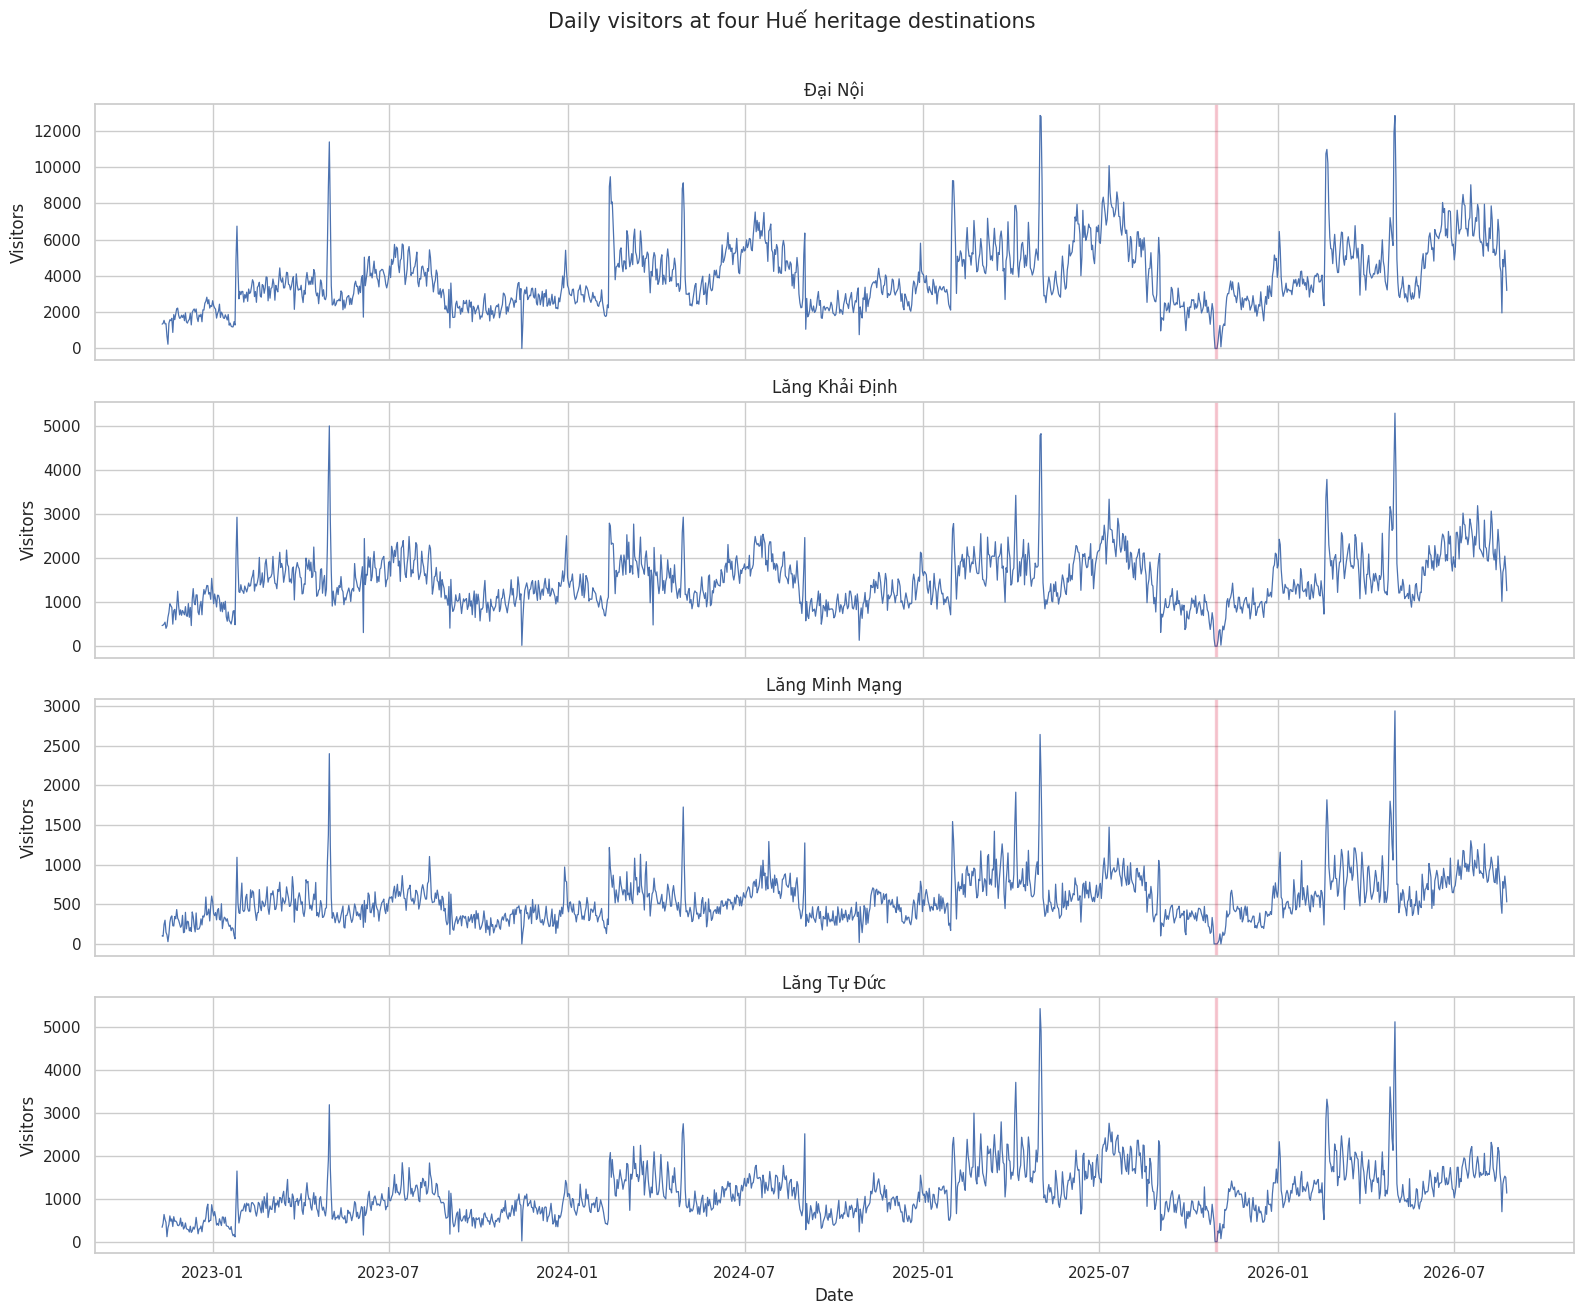

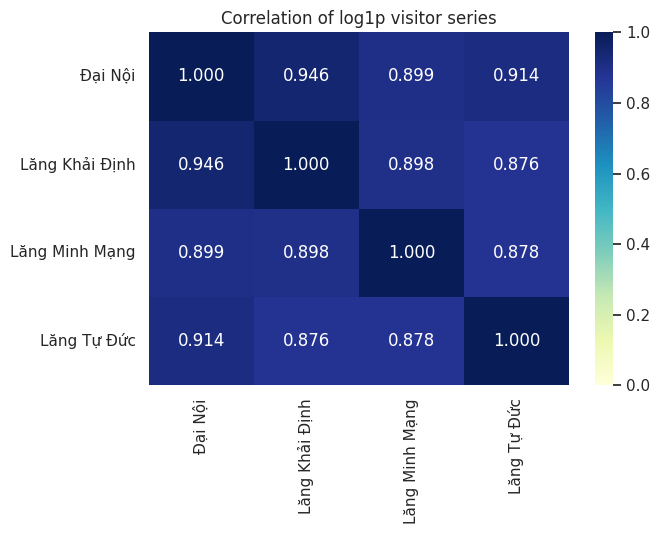

In [4]:
total_cols = [f'{k}__visitors' for k in SITE_KEYS]
totals_plot = wide.set_index('date')[total_cols].copy()
totals_plot.columns = SITE_NAMES

fig, axes = plt.subplots(N_SITES, 1, figsize=(16, 13), sharex=True)
for ax, site_name in zip(axes, SITE_NAMES):
    ax.plot(totals_plot.index, totals_plot[site_name], lw=0.9)
    for closure_date in sorted(CONFIRMED_CLOSURE_DATES):
        ax.axvline(closure_date, color='crimson', alpha=0.2, lw=1)
    ax.set_title(site_name)
    ax.set_ylabel('Visitors')
axes[-1].set_xlabel('Date')
fig.suptitle('Daily visitors at four Huế heritage destinations', y=1.01, fontsize=15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_daily_visitors.png', dpi=300, bbox_inches='tight')
plt.show()

corr = np.log1p(totals_plot).corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Correlation of log1p visitor series')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'eda_cross_destination_correlation.png', dpi=300, bbox_inches='tight')
plt.show()
corr.to_csv(TABLE_DIR / 'cross_destination_correlation.csv', encoding='utf-8-sig')


## 5. Tạo đặc trưng nhân quả và chuẩn hóa train-only

`X_seq` chứa lịch sử visitors tổng/nội địa/quốc tế của cả bốn điểm đến cùng lịch sử lịch. `X_future` chỉ chứa các biến biết trước tại ngày đích. Mục tiêu là `log1p(visitors)` của bốn điểm đến tại horizon 1, 7 và 14.


In [5]:
dates = pd.DatetimeIndex(wide['date'])
vn_holidays = holidays.Vietnam(years=range(dates.min().year, dates.max().year + 1))

def make_calendar_features(date_index):
    idx = pd.DatetimeIndex(date_index)
    dow = idx.dayofweek.to_numpy()
    month = idx.month.to_numpy()
    doy = idx.dayofyear.to_numpy()
    data = {
        'dow_sin': np.sin(2 * np.pi * dow / 7),
        'dow_cos': np.cos(2 * np.pi * dow / 7),
        'month_sin': np.sin(2 * np.pi * (month - 1) / 12),
        'month_cos': np.cos(2 * np.pi * (month - 1) / 12),
        'doy_sin': np.sin(2 * np.pi * (doy - 1) / 365.25),
        'doy_cos': np.cos(2 * np.pi * (doy - 1) / 365.25),
        'is_weekend': (dow >= 5).astype(float),
        'is_holiday': np.array([float(ts.date() in vn_holidays) for ts in idx]),
        'is_confirmed_closure': np.array([float(ts.normalize() in CONFIRMED_CLOSURE_DATES) for ts in idx]),
        'trend_years': ((idx - COMMON_START).days.to_numpy() / 365.25),
    }
    for day in range(7):
        data[f'dow_{day}'] = (dow == day).astype(float)
    return pd.DataFrame(data, index=idx)

calendar_raw = make_calendar_features(dates)
history_parts = []
history_names = []
for site_key in SITE_KEYS:
    for suffix in ['visitors', 'domestic', 'international']:
        col = f'{site_key}__{suffix}'
        history_parts.append(np.log1p(wide[col].to_numpy(dtype=float))[:, None])
        history_names.append(f'log1p_{col}')
history_raw = np.concatenate(history_parts, axis=1)
seq_raw = np.concatenate([history_raw, calendar_raw.to_numpy(dtype=float)], axis=1)
seq_feature_names = history_names + calendar_raw.columns.tolist()
future_raw = calendar_raw.to_numpy(dtype=float)
future_feature_names = calendar_raw.columns.tolist()

target_raw = wide[total_cols].to_numpy(dtype=float)
target_log = np.log1p(target_raw)
split_arr = wide['split'].to_numpy()
train_row_mask = split_arr == 'train'

seq_scaler = StandardScaler().fit(seq_raw[train_row_mask])
future_scaler = StandardScaler().fit(future_raw[train_row_mask])
target_scaler = StandardScaler().fit(target_log[train_row_mask])
seq_scaled = seq_scaler.transform(seq_raw).astype('float32')
future_scaled = future_scaler.transform(future_raw).astype('float32')
target_scaled_daily = target_scaler.transform(target_log).astype('float32')

def inverse_target(pred_scaled):
    pred_scaled = np.asarray(pred_scaled)
    n = pred_scaled.shape[0]
    pred_log = target_scaler.inverse_transform(pred_scaled.reshape(n * len(HORIZONS), N_SITES))
    pred_raw = np.expm1(pred_log).reshape(n, len(HORIZONS), N_SITES)
    return np.clip(pred_raw, 0, None)

print('Sequence features:', len(seq_feature_names))
print('Known-future features:', len(future_feature_names))
print('Target scaler fitted rows:', int(train_row_mask.sum()), '(train only)')


Sequence features: 29
Known-future features: 17
Target scaler fitted rows: 966 (train only)


## 6. Tạo mẫu direct multi-horizon

Một origin sử dụng dữ liệu đến ngày `origin - 1`; các đích là `origin`, `origin + 6` và `origin + 13`. Mẫu chỉ thuộc một split khi toàn bộ ba ngày đích cùng nằm trong split đó.


In [6]:
bundle_cache = {}

def make_supervised(lookback):
    if lookback in bundle_cache:
        return bundle_cache[lookback]
    storage = {s: {'X_seq': [], 'X_future': [], 'y_scaled': [], 'y_raw': [],
                   'origin_idx': [], 'origin_date': [], 'target_dates': []}
               for s in ['train', 'validation', 'test']}
    for origin in range(lookback, len(wide) - MAX_HORIZON + 1):
        target_indices = np.array([origin + h - 1 for h in HORIZONS], dtype=int)
        target_splits = split_arr[target_indices]
        if len(set(target_splits.tolist())) != 1:
            continue
        split_name = target_splits[0]
        if split_name not in storage:
            continue
        bucket = storage[split_name]
        bucket['X_seq'].append(seq_scaled[origin - lookback:origin])
        bucket['X_future'].append(future_scaled[target_indices])
        bucket['y_scaled'].append(target_scaled_daily[target_indices].reshape(-1))
        bucket['y_raw'].append(target_raw[target_indices])
        bucket['origin_idx'].append(origin)
        bucket['origin_date'].append(dates[origin])
        bucket['target_dates'].append(dates[target_indices].to_numpy())

    for split_name, bucket in storage.items():
        bucket['X_seq'] = np.asarray(bucket['X_seq'], dtype='float32')
        bucket['X_future'] = np.asarray(bucket['X_future'], dtype='float32')
        bucket['y_scaled'] = np.asarray(bucket['y_scaled'], dtype='float32')
        bucket['y_raw'] = np.asarray(bucket['y_raw'], dtype='float64')
        bucket['origin_idx'] = np.asarray(bucket['origin_idx'], dtype=int)
        bucket['origin_date'] = pd.DatetimeIndex(bucket['origin_date'])
        bucket['target_dates'] = np.asarray(bucket['target_dates'], dtype='datetime64[ns]')
        if len(bucket['X_seq']) == 0:
            raise ValueError(f'Không có mẫu {split_name} cho lookback={lookback}')
    bundle_cache[lookback] = storage
    return storage

for lookback in LOOKBACK_CANDIDATES:
    b = make_supervised(lookback)
    print(lookback, {s: b[s]['X_seq'].shape for s in b})

REFERENCE_LOOKBACK = 84 if 84 in LOOKBACK_CANDIDATES else LOOKBACK_CANDIDATES[-1]
reference_bundle = make_supervised(REFERENCE_LOOKBACK)

def assert_eval_alignment(bundle):
    for split_name in ['validation', 'test']:
        left = bundle[split_name]['origin_date'].to_numpy()
        right = reference_bundle[split_name]['origin_date'].to_numpy()
        if not np.array_equal(left, right):
            raise AssertionError(f'Origin dates không đồng nhất ở {split_name}.')

for lookback in LOOKBACK_CANDIDATES:
    assert_eval_alignment(make_supervised(lookback))
print('Đã xác nhận validation/test dùng cùng origin cho mọi lookback.')


28 {'train': (925, 28, 29), 'validation': (195, 28, 29), 'test': (197, 28, 29)}
56 {'train': (897, 56, 29), 'validation': (195, 56, 29), 'test': (197, 56, 29)}
84 {'train': (869, 84, 29), 'validation': (195, 84, 29), 'test': (197, 84, 29)}
112 {'train': (841, 112, 29), 'validation': (195, 112, 29), 'test': (197, 112, 29)}
Đã xác nhận validation/test dùng cùng origin cho mọi lookback.


## 7. Hàm đánh giá, Seasonal Naive-7 và lưu dự báo


In [7]:
def aggregate_rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))

def seasonal_naive_predict(bundle, split_name, season=7):
    bucket = bundle[split_name]
    preds = np.empty_like(bucket['y_raw'], dtype=float)
    for i, origin in enumerate(bucket['origin_idx']):
        for hi, horizon in enumerate(HORIZONS):
            target_idx = origin + horizon - 1
            required_lag = season * math.ceil(horizon / season)
            source_idx = target_idx - required_lag
            if source_idx > origin - 1:
                raise AssertionError('Seasonal naive đã sử dụng quan sát tương lai.')
            preds[i, hi, :] = target_raw[source_idx, :]
    return preds

val_predictions = {'SeasonalNaive7': seasonal_naive_predict(reference_bundle, 'validation')}
test_predictions = {'SeasonalNaive7': seasonal_naive_predict(reference_bundle, 'test')}
test_prediction_std = {'SeasonalNaive7': np.zeros_like(test_predictions['SeasonalNaive7'])}
model_bundles = {'SeasonalNaive7': reference_bundle}
print('Seasonal Naive validation RMSE:', aggregate_rmse(reference_bundle['validation']['y_raw'], val_predictions['SeasonalNaive7']))


Seasonal Naive validation RMSE: 733.5213829403812


## 8. ARX–Ridge: mô hình tuyến tính truyền thống

Ridge dùng cửa sổ lịch sử đã làm phẳng và lịch tương lai đã biết. `alpha` và lookback chỉ được chọn bằng validation. Sau khi chọn, mô hình được fit lại trên train + validation rồi mới dự báo test.


In [8]:
# Dải rộng cần thiết vì ma trận lag có hàng nghìn cột và tương quan mạnh.
RIDGE_ALPHAS = np.logspace(-3, 5, 17)
ridge_search_rows = []
best_ridge = None

for lookback in LOOKBACK_CANDIDATES:
    bundle = make_supervised(lookback)
    X_train = np.concatenate([
        bundle['train']['X_seq'].reshape(len(bundle['train']['X_seq']), -1),
        bundle['train']['X_future'].reshape(len(bundle['train']['X_future']), -1)
    ], axis=1)
    X_val = np.concatenate([
        bundle['validation']['X_seq'].reshape(len(bundle['validation']['X_seq']), -1),
        bundle['validation']['X_future'].reshape(len(bundle['validation']['X_future']), -1)
    ], axis=1)
    y_train = bundle['train']['y_scaled']
    y_val_raw = bundle['validation']['y_raw']

    for alpha in RIDGE_ALPHAS:
        ridge = Ridge(alpha=float(alpha), fit_intercept=True)
        ridge.fit(X_train, y_train)
        val_pred = inverse_target(ridge.predict(X_val))
        score = aggregate_rmse(y_val_raw, val_pred)
        row = {'lookback': lookback, 'alpha': float(alpha), 'validation_RMSE': score}
        ridge_search_rows.append(row)
        if best_ridge is None or score < best_ridge['validation_RMSE']:
            best_ridge = row.copy()

ridge_search_df = pd.DataFrame(ridge_search_rows)
ridge_search_df.to_csv(TABLE_DIR / 'ridge_validation_search.csv', index=False, encoding='utf-8-sig')
print('Best ARX-Ridge:', best_ridge)

ridge_bundle = make_supervised(int(best_ridge['lookback']))
def flatten_inputs(bucket):
    return np.concatenate([
        bucket['X_seq'].reshape(len(bucket['X_seq']), -1),
        bucket['X_future'].reshape(len(bucket['X_future']), -1)
    ], axis=1)

# Validation prediction từ mô hình chỉ fit train.
ridge_stage1 = Ridge(alpha=best_ridge['alpha'])
ridge_stage1.fit(flatten_inputs(ridge_bundle['train']), ridge_bundle['train']['y_scaled'])
val_predictions['ARX-Ridge'] = inverse_target(ridge_stage1.predict(flatten_inputs(ridge_bundle['validation'])))

# Refit train + validation, sau đó dự báo test.
X_trainval = np.concatenate([flatten_inputs(ridge_bundle['train']), flatten_inputs(ridge_bundle['validation'])])
y_trainval = np.concatenate([ridge_bundle['train']['y_scaled'], ridge_bundle['validation']['y_scaled']])
ridge_final = Ridge(alpha=best_ridge['alpha'])
ridge_final.fit(X_trainval, y_trainval)
test_predictions['ARX-Ridge'] = inverse_target(ridge_final.predict(flatten_inputs(ridge_bundle['test'])))
test_prediction_std['ARX-Ridge'] = np.zeros_like(test_predictions['ARX-Ridge'])
model_bundles['ARX-Ridge'] = ridge_bundle

import joblib
joblib.dump(ridge_final, MODEL_DIR / 'ARX_Ridge.joblib')


Best ARX-Ridge: {'lookback': 28, 'alpha': 3162.2776601683795, 'validation_RMSE': 586.3448138576778}


['/content/drive/MyDrive/NCS/Tourist/2-results/models/ARX_Ridge.joblib']

## 9. Kiến trúc LSTM, GRU, 1D-CNN và Transformer

Các kiến trúc được giữ nhỏ để phù hợp với khoảng 1.384 ngày chung. Đầu ra là 12 giá trị: 3 horizon × 4 địa điểm.


In [9]:
def build_deep_model(model_name, seq_shape, future_shape, params):
    seq_input = keras.Input(shape=seq_shape, name='past_sequence')
    future_input = keras.Input(shape=future_shape, name='known_future')
    dropout = float(params['dropout'])

    if model_name in ['LSTM', 'GRU']:
        rnn_cls = layers.LSTM if model_name == 'LSTM' else layers.GRU
        units = int(params['units'])
        n_layers = int(params['n_layers'])
        x = seq_input
        for layer_idx in range(n_layers):
            return_sequences = layer_idx < n_layers - 1
            x = rnn_cls(units, return_sequences=return_sequences)(x)
            x = layers.Dropout(dropout)(x)

    elif model_name == '1D-CNN':
        filters = int(params['filters'])
        kernel_size = int(params['kernel_size'])
        n_blocks = int(params['n_blocks'])
        x = layers.Dense(filters)(seq_input)
        for dilation in [1, 2, 4][:n_blocks]:
            residual = x
            y = layers.Conv1D(filters, kernel_size, padding='causal', dilation_rate=dilation,
                              activation='relu')(x)
            y = layers.BatchNormalization()(y)
            y = layers.Dropout(dropout)(y)
            y = layers.Conv1D(filters, 1, padding='same')(y)
            x = layers.Add()([residual, y])
            x = layers.Activation('relu')(x)
        x = layers.GlobalAveragePooling1D()(x)

    elif model_name == 'Transformer':
        d_model = int(params['d_model'])
        num_heads = int(params['num_heads'])
        n_layers = int(params['n_layers'])
        ff_dim = int(params['ff_dim'])
        x = layers.Dense(d_model)(seq_input)
        positions = tf.range(start=0, limit=seq_shape[0], delta=1)
        position_embedding = layers.Embedding(input_dim=seq_shape[0], output_dim=d_model)(positions)
        x = x + position_embedding
        for _ in range(n_layers):
            attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads,
                                             dropout=dropout)(x, x)
            x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(dropout)(attn))
            ff = layers.Dense(ff_dim, activation='gelu')(x)
            ff = layers.Dense(d_model)(ff)
            x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(dropout)(ff))
        x = layers.GlobalAveragePooling1D()(x)
    else:
        raise ValueError(model_name)

    future_branch = layers.Flatten()(future_input)
    future_branch = layers.Dense(int(params['dense_units']), activation='relu')(future_branch)
    merged = layers.Concatenate()([x, future_branch])
    merged = layers.Dense(int(params['dense_units']), activation='relu')(merged)
    merged = layers.Dropout(dropout)(merged)
    output = layers.Dense(N_OUTPUTS, name='forecast')(merged)

    model = keras.Model([seq_input, future_input], output, name=model_name.replace('-', '_'))
    optimizer = keras.optimizers.Adam(learning_rate=float(params['learning_rate']), clipnorm=1.0)
    model.compile(optimizer=optimizer, loss=keras.losses.Huber(delta=1.0), metrics=['mae'])
    return model

DEFAULT_PARAMS = {
    'LSTM': {'lookback': 84, 'units': 64, 'n_layers': 1, 'dense_units': 64,
             'dropout': 0.20, 'learning_rate': 1e-3, 'batch_size': 32},
    'GRU': {'lookback': 84, 'units': 64, 'n_layers': 1, 'dense_units': 64,
            'dropout': 0.20, 'learning_rate': 1e-3, 'batch_size': 32},
    '1D-CNN': {'lookback': 84, 'filters': 64, 'kernel_size': 3, 'n_blocks': 3,
               'dense_units': 64, 'dropout': 0.20, 'learning_rate': 1e-3, 'batch_size': 32},
    'Transformer': {'lookback': 84, 'd_model': 64, 'num_heads': 4, 'n_layers': 1,
                    'ff_dim': 128, 'dense_units': 64, 'dropout': 0.20,
                    'learning_rate': 5e-4, 'batch_size': 32},
}


## 10. Bayesian Optimization bằng Optuna

Mỗi mô hình học sâu có cùng số trial. Hàm mục tiêu là RMSE validation trên đơn vị visitors thực. Test hoàn toàn không xuất hiện trong cell này.


In [10]:
def suggest_params(trial, model_name):
    params = {
        'lookback': trial.suggest_categorical('lookback', LOOKBACK_CANDIDATES),
        'dense_units': trial.suggest_categorical('dense_units', [32, 64, 96]),
        'dropout': trial.suggest_float('dropout', 0.10, 0.35),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 3e-3, log=True),
        'batch_size': trial.suggest_categorical('batch_size', [16, 32, 64]),
    }
    if model_name in ['LSTM', 'GRU']:
        params.update({
            'units': trial.suggest_categorical('units', [32, 64, 96]),
            'n_layers': trial.suggest_int('n_layers', 1, 2),
        })
    elif model_name == '1D-CNN':
        params.update({
            'filters': trial.suggest_categorical('filters', [32, 64, 96]),
            'kernel_size': trial.suggest_categorical('kernel_size', [3, 5]),
            'n_blocks': trial.suggest_int('n_blocks', 2, 3),
        })
    elif model_name == 'Transformer':
        params.update({
            'd_model': trial.suggest_categorical('d_model', [32, 64]),
            'num_heads': trial.suggest_categorical('num_heads', [2, 4]),
            'n_layers': trial.suggest_int('n_layers', 1, 2),
            'ff_dim': trial.suggest_categorical('ff_dim', [64, 128]),
        })
    return params

best_params = {}
tuning_summary = []

for model_index, model_name in enumerate(DL_MODELS):
    if not RUN_OPTUNA:
        best_params[model_name] = DEFAULT_PARAMS[model_name].copy()
        continue

    print('\nTuning', model_name)
    def objective(trial):
        tf.keras.backend.clear_session()
        gc.collect()
        set_all_seeds(SEED + model_index * 1000 + trial.number)
        params = suggest_params(trial, model_name)
        bundle = make_supervised(int(params['lookback']))
        train_b = bundle['train']
        val_b = bundle['validation']
        model = build_deep_model(model_name, train_b['X_seq'].shape[1:],
                                 train_b['X_future'].shape[1:], params)
        callbacks = [
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                          restore_best_weights=True, min_delta=1e-5),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=max(3, PATIENCE // 2),
                                              factor=0.5, min_lr=1e-6),
        ]
        history = model.fit(
            [train_b['X_seq'], train_b['X_future']], train_b['y_scaled'],
            validation_data=([val_b['X_seq'], val_b['X_future']], val_b['y_scaled']),
            epochs=MAX_EPOCHS_TUNE, batch_size=int(params['batch_size']),
            shuffle=False, verbose=0, callbacks=callbacks,
        )
        pred = inverse_target(model.predict([val_b['X_seq'], val_b['X_future']], verbose=0))
        score = aggregate_rmse(val_b['y_raw'], pred)
        trial.set_user_attr('best_epoch', int(np.argmin(history.history['val_loss']) + 1))
        trial.set_user_attr('parameter_count', int(model.count_params()))
        del model
        tf.keras.backend.clear_session()
        gc.collect()
        return score

    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=SEED + model_index),
        study_name=f'Hue_{model_name.replace("-", "_")}',
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    params = study.best_params.copy()
    params['best_epoch_tuning'] = int(study.best_trial.user_attrs.get('best_epoch', 50))
    best_params[model_name] = params
    study.trials_dataframe().to_csv(
        OPTUNA_DIR / f'{model_name.replace("-", "_")}_trials.csv', index=False, encoding='utf-8-sig')
    tuning_summary.append({
        'model': model_name,
        'best_validation_RMSE': study.best_value,
        'best_trial': study.best_trial.number,
        'best_epoch_tuning': params['best_epoch_tuning'],
    })
    print('Best:', model_name, study.best_value, params)

with open(LOG_DIR / 'best_hyperparameters.json', 'w', encoding='utf-8') as handle:
    json.dump({'ARX-Ridge': best_ridge, **best_params}, handle, ensure_ascii=False, indent=2)
if tuning_summary:
    pd.DataFrame(tuning_summary).to_csv(TABLE_DIR / 'optuna_summary.csv', index=False, encoding='utf-8-sig')


[I 2026-08-28 13:49:22,533] A new study created in memory with name: Hue_LSTM



Tuning LSTM


  0%|          | 0/15 [00:00<?, ?it/s]

[I 2026-08-28 13:49:51,156] Trial 0 finished with value: 583.9299587545087 and parameters: {'lookback': 84, 'dense_units': 64, 'dropout': 0.32792879546131865, 'learning_rate': 0.000667733415294117, 'batch_size': 16, 'units': 64, 'n_layers': 1}. Best is trial 0 with value: 583.9299587545087.
[I 2026-08-28 13:50:15,809] Trial 1 finished with value: 647.0322358849611 and parameters: {'lookback': 112, 'dense_units': 96, 'dropout': 0.2607242374437928, 'learning_rate': 0.00022310152372121493, 'batch_size': 16, 'units': 96, 'n_layers': 2}. Best is trial 0 with value: 583.9299587545087.


[I 2026-08-28 13:50:40,095] Trial 2 finished with value: 608.1155926187078 and parameters: {'lookback': 28, 'dense_units': 32, 'dropout': 0.21272089011853546, 'learning_rate': 0.002445619553636844, 'batch_size': 16, 'units': 96, 'n_layers': 2}. Best is trial 0 with value: 583.9299587545087.


[I 2026-08-28 13:50:52,178] Trial 3 finished with value: 585.3786799098635 and parameters: {'lookback': 112, 'dense_units': 64, 'dropout': 0.2629551828646551, 'learning_rate': 0.002962476532839522, 'batch_size': 64, 'units': 32, 'n_layers': 1}. Best is trial 0 with value: 583.9299587545087.
[I 2026-08-28 13:51:02,315] Trial 4 finished with value: 659.0709740486304 and parameters: {'lookback': 28, 'dense_units': 96, 'dropout': 0.19221369595219318, 'learning_rate': 0.0005570357513312092, 'batch_size': 64, 'units': 96, 'n_layers': 2}. Best is trial 0 with value: 583.9299587545087.
[I 2026-08-28 13:51:16,438] Trial 5 finished with value: 692.266754751533 and parameters: {'lookback': 112, 'dense_units': 32, 'dropout': 0.3053942932760474, 'learning_rate': 0.0018174806019608037, 'batch_size': 64, 'units': 32, 'n_layers': 2}. Best is trial 0 with value: 583.9299587545087.
[I 2026-08-28 13:51:27,224] Trial 6 finished with value: 666.4780588084095 and parameters: {'lookback': 28, 'dense_units': 

... (8 outputs left out)

[I 2026-08-28 14:05:52,514] A new study created in memory with name: Hue_Transformer


[I 2026-08-28 14:05:52,494] Trial 14 finished with value: 687.2239574522127 and parameters: {'lookback': 84, 'dense_units': 96, 'dropout': 0.3460793949202262, 'learning_rate': 0.0018361071243918755, 'batch_size': 32, 'filters': 32, 'kernel_size': 5, 'n_blocks': 3}. Best is trial 3 with value: 646.3797340233789.
Best: 1D-CNN 646.3797340233789 {'lookback': 84, 'dense_units': 96, 'dropout': 0.12834714045503087, 'learning_rate': 0.00280987361408003, 'batch_size': 16, 'filters': 32, 'kernel_size': 5, 'n_blocks': 3, 'best_epoch_tuning': 59}

Tuning Transformer


  0%|          | 0/15 [00:00<?, ?it/s]

[I 2026-08-28 14:06:17,544] Trial 0 finished with value: 605.9693446050289 and parameters: {'lookback': 84, 'dense_units': 96, 'dropout': 0.21255778270144143, 'learning_rate': 0.0011373890484378728, 'batch_size': 32, 'd_model': 32, 'num_heads': 4, 'n_layers': 1, 'ff_dim': 64}. Best is trial 0 with value: 605.9693446050289.
[I 2026-08-28 14:07:04,267] Trial 1 finished with value: 612.2010837101221 and parameters: {'lookback': 56, 'dense_units': 32, 'dropout': 0.30939694885317803, 'learning_rate': 0.0020669421336082737, 'batch_size': 16, 'd_model': 32, 'num_heads': 4, 'n_layers': 2, 'ff_dim': 128}. Best is trial 0 with value: 605.9693446050289.
[I 2026-08-28 14:07:25,885] Trial 2 finished with value: 676.982872742737 and parameters: {'lookback': 112, 'dense_units': 96, 'dropout': 0.10920863823360782, 'learning_rate': 0.000464598720195833, 'batch_size': 64, 'd_model': 32, 'num_heads': 2, 'n_layers': 1, 'ff_dim': 64}. Best is trial 0 with value: 605.9693446050289.
[I 2026-08-28 14:08:00,38

## 11. Huấn luyện cuối cùng và ensemble qua nhiều seed

Giai đoạn 1 fit train và dùng validation để xác định epoch tốt nhất. Giai đoạn 2 xây dựng lại mô hình, fit trên train + validation đúng số epoch đã chọn, sau đó dự báo test. Dự báo test được trung bình qua ba seed ở chế độ bài báo.


In [11]:
histories = {}
best_epochs = {}
parameter_counts = {'ARX-Ridge': int(ridge_final.coef_.size + ridge_final.intercept_.size)}

for model_index, model_name in enumerate(DL_MODELS):
    print('\nFinal training:', model_name)
    params = best_params[model_name].copy()
    params.pop('best_epoch_tuning', None)
    lookback = int(params['lookback'])
    bundle = make_supervised(lookback)
    model_bundles[model_name] = bundle
    train_b, val_b, test_b = bundle['train'], bundle['validation'], bundle['test']

    # Stage 1: train -> validation.
    tf.keras.backend.clear_session()
    set_all_seeds(SEED)
    stage1 = build_deep_model(model_name, train_b['X_seq'].shape[1:],
                              train_b['X_future'].shape[1:], params)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE,
                                      restore_best_weights=True, min_delta=1e-5),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=max(3, PATIENCE // 2),
                                          factor=0.5, min_lr=1e-6),
    ]
    history = stage1.fit(
        [train_b['X_seq'], train_b['X_future']], train_b['y_scaled'],
        validation_data=([val_b['X_seq'], val_b['X_future']], val_b['y_scaled']),
        epochs=MAX_EPOCHS_FINAL_STAGE1, batch_size=int(params['batch_size']),
        shuffle=False, verbose=1, callbacks=callbacks,
    )
    histories[model_name] = pd.DataFrame(history.history)
    best_epoch = int(np.argmin(history.history['val_loss']) + 1)
    best_epochs[model_name] = best_epoch
    parameter_counts[model_name] = int(stage1.count_params())
    val_predictions[model_name] = inverse_target(
        stage1.predict([val_b['X_seq'], val_b['X_future']], verbose=0))
    del stage1
    tf.keras.backend.clear_session()
    gc.collect()

    # Stage 2: refit train + validation, trung bình dự báo qua seed.
    X_seq_trainval = np.concatenate([train_b['X_seq'], val_b['X_seq']])
    X_future_trainval = np.concatenate([train_b['X_future'], val_b['X_future']])
    y_trainval = np.concatenate([train_b['y_scaled'], val_b['y_scaled']])
    seed_predictions = []
    for final_seed in FINAL_SEEDS:
        tf.keras.backend.clear_session()
        set_all_seeds(final_seed)
        final_model = build_deep_model(model_name, train_b['X_seq'].shape[1:],
                                       train_b['X_future'].shape[1:], params)
        final_model.fit(
            [X_seq_trainval, X_future_trainval], y_trainval,
            epochs=max(1, best_epoch), batch_size=int(params['batch_size']),
            shuffle=False, verbose=0,
        )
        pred_seed = inverse_target(
            final_model.predict([test_b['X_seq'], test_b['X_future']], verbose=0))
        seed_predictions.append(pred_seed)
        final_model.save(MODEL_DIR / f'{model_name.replace("-", "_")}_seed{final_seed}.keras')
        del final_model
        tf.keras.backend.clear_session()
        gc.collect()

    seed_predictions = np.stack(seed_predictions, axis=0)
    test_predictions[model_name] = seed_predictions.mean(axis=0)
    test_prediction_std[model_name] = seed_predictions.std(axis=0)
    histories[model_name].to_csv(
        LOG_DIR / f'{model_name.replace("-", "_")}_training_history.csv',
        index_label='epoch', encoding='utf-8-sig')
    print(model_name, '| best epoch:', best_epoch, '| params:', parameter_counts[model_name])



Final training: LSTM
Epoch 1/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.3679 - mae: 0.7299 - val_loss: 0.6831 - val_mae: 1.0537 - learning_rate: 4.7970e-04
Epoch 2/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2676 - mae: 0.5952 - val_loss: 0.6007 - val_mae: 0.9453 - learning_rate: 4.7970e-04
Epoch 3/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2276 - mae: 0.5374 - val_loss: 0.5729 - val_mae: 0.9064 - learning_rate: 4.7970e-04
Epoch 4/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2070 - mae: 0.5045 - val_loss: 0.5623 - val_mae: 0.8926 - learning_rate: 4.7970e-04
Epoch 5/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1936 - mae: 0.4836 - val_loss: 0.5625 - val_mae: 0.8925 - learning_rate: 4.7970e-04
Epoch 6/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1834 - mae: 0.4680 - val_loss: 0.5682 - val_mae: 0.9036 - learning_rate: 4.7970e-04
Epoch 7/200
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1781 - mae: 0.4598 - val_loss: 0.5582 - 

## 12. Kịch bản đóng cửa và validation-weighted ensemble

- `model_only`: dự báo thuần túy của mô hình.
- `operational_closure`: ghi đè bằng 0 cho ngày đóng cửa đã xác nhận.

Ensemble chọn tối đa ba mô hình đơn tốt nhất theo từng địa điểm/horizon trên validation và học trọng số không âm, tổng bằng 1. Không dùng test để học trọng số.


In [12]:
def apply_closure_override(pred, bucket):
    adjusted = np.asarray(pred).copy()
    if not APPLY_CONFIRMED_CLOSURE_OVERRIDE:
        return adjusted
    for sample_idx in range(len(adjusted)):
        for h_idx in range(len(HORIZONS)):
            target_date = pd.Timestamp(bucket['target_dates'][sample_idx, h_idx]).normalize()
            if target_date in CONFIRMED_CLOSURE_DATES:
                adjusted[sample_idx, h_idx, :] = 0.0
    return adjusted

val_predictions_operational = {
    name: apply_closure_override(pred, reference_bundle['validation'])
    for name, pred in val_predictions.items()
}
test_predictions_operational = {
    name: apply_closure_override(pred, reference_bundle['test'])
    for name, pred in test_predictions.items()
}

ensemble_candidates = ['ARX-Ridge'] + DL_MODELS
val_actual = reference_bundle['validation']['y_raw']
ensemble_val = np.zeros_like(val_actual, dtype=float)
ensemble_test = np.zeros_like(reference_bundle['test']['y_raw'], dtype=float)
ensemble_weight_rows = []

def fit_simplex_weights(pred_matrix, actual):
    n_models = pred_matrix.shape[1]
    objective = lambda w: np.mean((pred_matrix @ w - actual) ** 2)
    result = minimize(
        objective,
        x0=np.repeat(1 / n_models, n_models),
        method='SLSQP', bounds=[(0.0, 1.0)] * n_models,
        constraints={'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0},
    )
    if not result.success or not np.all(np.isfinite(result.x)):
        rmses = np.sqrt(np.mean((pred_matrix - actual[:, None]) ** 2, axis=0))
        inv = 1 / np.maximum(rmses, 1e-8)
        return inv / inv.sum()
    weights = np.clip(result.x, 0, 1)
    return weights / weights.sum()

for h_idx, horizon in enumerate(HORIZONS):
    for s_idx, site_name in enumerate(SITE_NAMES):
        ranking = []
        for model_name in ensemble_candidates:
            rmse = aggregate_rmse(
                val_actual[:, h_idx, s_idx],
                val_predictions_operational[model_name][:, h_idx, s_idx])
            ranking.append((rmse, model_name))
        selected = [name for _, name in sorted(ranking)[:TOP_K_ENSEMBLE]]
        P_val = np.column_stack([
            val_predictions_operational[name][:, h_idx, s_idx] for name in selected])
        P_test = np.column_stack([
            test_predictions_operational[name][:, h_idx, s_idx] for name in selected])
        y_val = val_actual[:, h_idx, s_idx]
        weights = fit_simplex_weights(P_val, y_val)
        ensemble_val[:, h_idx, s_idx] = P_val @ weights
        ensemble_test[:, h_idx, s_idx] = P_test @ weights
        for model_name, weight in zip(selected, weights):
            ensemble_weight_rows.append({
                'destination': site_name, 'horizon': horizon,
                'component_model': model_name, 'weight': float(weight),
            })

val_predictions_operational['Ensemble'] = ensemble_val
test_predictions_operational['Ensemble'] = ensemble_test
test_prediction_std['Ensemble'] = np.zeros_like(ensemble_test)
ensemble_weights_df = pd.DataFrame(ensemble_weight_rows)
ensemble_weights_df.to_csv(TABLE_DIR / 'ensemble_weights.csv', index=False, encoding='utf-8-sig')
display(ensemble_weights_df)


,destination,horizon,component_model,weight
0,Đại Nội,1,GRU,6.421044e-01
1,Đại Nội,1,ARX-Ridge,3.578952e-01
2,Đại Nội,1,LSTM,4.644479e-07
3,Lăng Khải Định,1,GRU,3.651266e-01
4,Lăng Khải Định,1,ARX-Ridge,3.604005e-01
5,Lăng Khải Định,1,LSTM,2.744729e-01
6,Lăng Minh Mạng,1,ARX-Ridge,7.257332e-01
7,Lăng Minh Mạng,1,LSTM,1.232350e-01
8,Lăng Minh Mạng,1,GRU,1.510319e-01
9,Lăng Tự Đức,1,ARX-Ridge,5.526509e-01


## 13. Xuất dự báo, metrics và Diebold–Mariano test


In [13]:
train_mase_scale = {}
for site_key, site_name in zip(SITE_KEYS, SITE_NAMES):
    train_values = wide.loc[wide['split'].eq('train'), f'{site_key}__visitors'].to_numpy(dtype=float)
    scale = np.mean(np.abs(train_values[7:] - train_values[:-7]))
    train_mase_scale[site_name] = max(float(scale), 1e-8)

def predictions_to_long(prediction_dict, split_name, scenario):
    bucket = reference_bundle[split_name]
    records = []
    for model_name, pred in prediction_dict.items():
        std_array = test_prediction_std.get(model_name, np.zeros_like(pred)) if split_name == 'test' else np.zeros_like(pred)
        for i in range(len(pred)):
            for h_idx, horizon in enumerate(HORIZONS):
                target_date = pd.Timestamp(bucket['target_dates'][i, h_idx])
                for s_idx, site_name in enumerate(SITE_NAMES):
                    records.append({
                        'split': split_name,
                        'scenario': scenario,
                        'model': model_name,
                        'origin_date': pd.Timestamp(bucket['origin_date'][i]),
                        'target_date': target_date,
                        'horizon': horizon,
                        'destination': site_name,
                        'actual': float(bucket['y_raw'][i, h_idx, s_idx]),
                        'prediction': float(pred[i, h_idx, s_idx]),
                        'seed_prediction_std': float(std_array[i, h_idx, s_idx]),
                        'confirmed_closure': target_date.normalize() in CONFIRMED_CLOSURE_DATES,
                    })
    return pd.DataFrame(records)

pred_frames = [
    predictions_to_long(val_predictions, 'validation', 'model_only'),
    predictions_to_long(test_predictions, 'test', 'model_only'),
    predictions_to_long(val_predictions_operational, 'validation', 'operational_closure'),
    predictions_to_long(test_predictions_operational, 'test', 'operational_closure'),
]
predictions_long = pd.concat(pred_frames, ignore_index=True)
predictions_long.to_csv(TABLE_DIR / 'predictions_all.csv', index=False, encoding='utf-8-sig')
predictions_long[predictions_long['split'].eq('validation')].to_csv(
    TABLE_DIR / 'predictions_validation.csv', index=False, encoding='utf-8-sig')
predictions_long[predictions_long['split'].eq('test')].to_csv(
    TABLE_DIR / 'predictions_test.csv', index=False, encoding='utf-8-sig')

def safe_smape(y, p):
    denom = np.abs(y) + np.abs(p)
    term = np.divide(2 * np.abs(y - p), denom, out=np.zeros_like(denom, dtype=float), where=denom > 0)
    return float(100 * np.mean(term))

def metric_row(group, destination=None):
    y = group['actual'].to_numpy(dtype=float)
    p = group['prediction'].to_numpy(dtype=float)
    if destination is None:
        scales = group['destination'].map(train_mase_scale).to_numpy(dtype=float)
        mase = float(np.mean(np.abs(y - p) / scales))
    else:
        mase = float(np.mean(np.abs(y - p)) / train_mase_scale[destination])
    return {
        'N': len(group),
        'MAE': mean_absolute_error(y, p),
        'RMSE': np.sqrt(mean_squared_error(y, p)),
        'sMAPE_pct': safe_smape(y, p),
        'WAPE_pct': 100 * np.sum(np.abs(y - p)) / max(np.sum(np.abs(y)), 1e-8),
        'MASE': mase,
        'R2': r2_score(y, p) if len(y) > 1 else np.nan,
    }

site_metric_rows = []
keys = ['split', 'scenario', 'model', 'destination', 'horizon']
for key_values, group in predictions_long.groupby(keys, sort=False):
    row = dict(zip(keys, key_values))
    row.update(metric_row(group, destination=row['destination']))
    site_metric_rows.append(row)
metrics_by_site = pd.DataFrame(site_metric_rows)

aggregate_metric_rows = []
agg_keys = ['split', 'scenario', 'model', 'horizon']
for key_values, group in predictions_long.groupby(agg_keys, sort=False):
    row = dict(zip(agg_keys, key_values))
    row.update(metric_row(group, destination=None))
    aggregate_metric_rows.append(row)
metrics_aggregate = pd.DataFrame(aggregate_metric_rows)

metrics_by_site.to_csv(TABLE_DIR / 'metrics_by_destination_horizon.csv', index=False, encoding='utf-8-sig')
metrics_aggregate.to_csv(TABLE_DIR / 'metrics_aggregate.csv', index=False, encoding='utf-8-sig')

def dm_hac_test(loss_model, loss_base, horizon):
    d = np.asarray(loss_model, dtype=float) - np.asarray(loss_base, dtype=float)
    d = d[np.isfinite(d)]
    n = len(d)
    if n < 20:
        return np.nan, np.nan
    d_mean = d.mean()
    centered = d - d_mean
    max_lag = min(max(horizon - 1, 0), n - 1)
    long_run_var = np.mean(centered ** 2)
    for lag in range(1, max_lag + 1):
        weight = 1 - lag / (max_lag + 1)
        gamma = np.mean(centered[lag:] * centered[:-lag])
        long_run_var += 2 * weight * gamma
    var_mean = max(long_run_var / n, 1e-12)
    statistic = d_mean / np.sqrt(var_mean)
    p_value = 2 * (1 - norm.cdf(abs(statistic)))
    return float(statistic), float(p_value)

test_op = predictions_long[
    predictions_long['split'].eq('test') &
    predictions_long['scenario'].eq('operational_closure')
].copy()
dm_rows = []
for site_name in SITE_NAMES:
    for horizon in HORIZONS:
        base = test_op[
            test_op['destination'].eq(site_name) & test_op['horizon'].eq(horizon) &
            test_op['model'].eq('SeasonalNaive7')
        ].sort_values('target_date')
        for model_name in [m for m in test_op['model'].unique() if m != 'SeasonalNaive7']:
            comp = test_op[
                test_op['destination'].eq(site_name) & test_op['horizon'].eq(horizon) &
                test_op['model'].eq(model_name)
            ].sort_values('target_date')
            merged_dm = base[['target_date', 'actual', 'prediction']].merge(
                comp[['target_date', 'prediction']], on='target_date', suffixes=('_base', '_model'))
            loss_base = (merged_dm['actual'] - merged_dm['prediction_base']) ** 2
            loss_model = (merged_dm['actual'] - merged_dm['prediction_model']) ** 2
            stat, p = dm_hac_test(loss_model, loss_base, horizon)
            dm_rows.append({
                'destination': site_name, 'horizon': horizon, 'model': model_name,
                'benchmark': 'SeasonalNaive7', 'DM_statistic': stat, 'p_value': p,
                'interpretation': 'negative statistic favors model',
            })
dm_results = pd.DataFrame(dm_rows)
valid_p = dm_results['p_value'].notna()
dm_results['p_holm'] = np.nan
if valid_p.any():
    dm_results.loc[valid_p, 'p_holm'] = multipletests(dm_results.loc[valid_p, 'p_value'], method='holm')[1]
dm_results.to_csv(TABLE_DIR / 'diebold_mariano_tests.csv', index=False, encoding='utf-8-sig')

test_summary = metrics_aggregate[
    metrics_aggregate['split'].eq('test') &
    metrics_aggregate['scenario'].eq('operational_closure')
].sort_values(['horizon', 'RMSE'])
display(test_summary)


,split,scenario,model,horizon,N,MAE,RMSE,sMAPE_pct,WAPE_pct,MASE,R2
66,test,operational_closure,GRU,1,788,333.051097,492.268648,14.542698,13.793871,0.859345,0.940029
75,test,operational_closure,Ensemble,1,788,336.734240,517.240614,15.655027,13.946415,0.918002,0.933790
60,test,operational_closure,ARX-Ridge,1,788,387.736133,665.015810,17.434670,16.058744,1.024183,0.890553
63,test,operational_closure,LSTM,1,788,401.495545,749.441474,17.249901,16.628613,1.031160,0.861000
72,test,operational_closure,Transformer,1,788,540.222264,898.488453,22.641071,22.374214,1.345186,0.800214
69,test,operational_closure,1D-CNN,1,788,744.830529,1096.457376,29.781693,30.848409,1.885399,0.702476
57,test,operational_closure,SeasonalNaive7,1,788,555.238579,1160.220826,22.274457,22.996140,1.392041,0.666865
67,test,operational_closure,GRU,7,788,413.898947,703.034076,17.890418,16.944116,1.070933,0.879307
76,test,operational_closure,Ensemble,7,788,429.589777,779.448336,18.930959,17.586464,1.117332,0.851644
64,test,operational_closure,LSTM,7,788,436.406552,825.081267,19.210101,17.865528,1.144243,0.833765


## 14. Loss curves và trực quan hóa kết quả test

Mô hình tuyến tính không có epoch loss; notebook vẽ validation RMSE theo `alpha` cho Ridge. Mô hình học sâu có train/validation loss curve riêng.


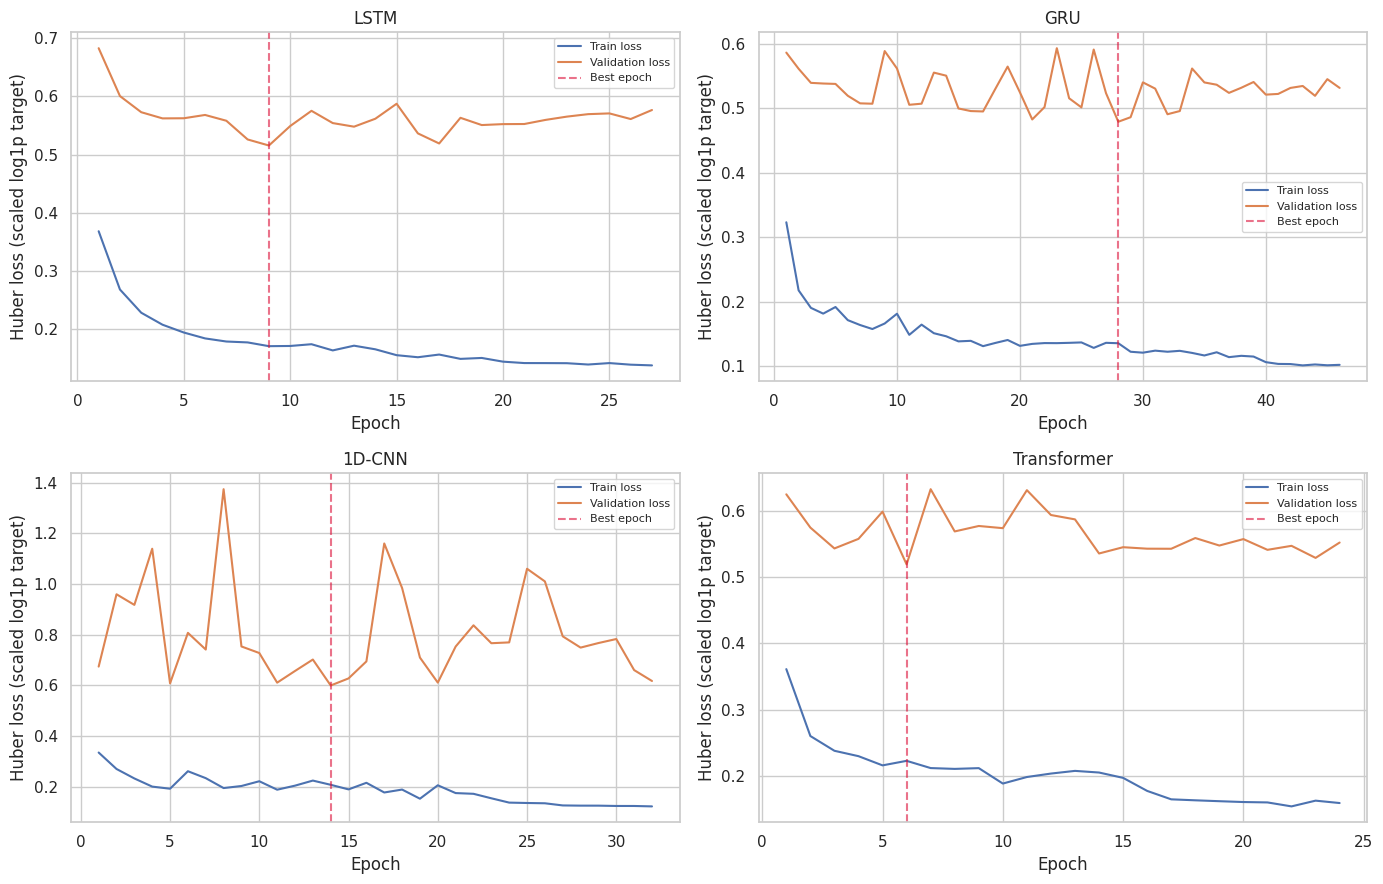

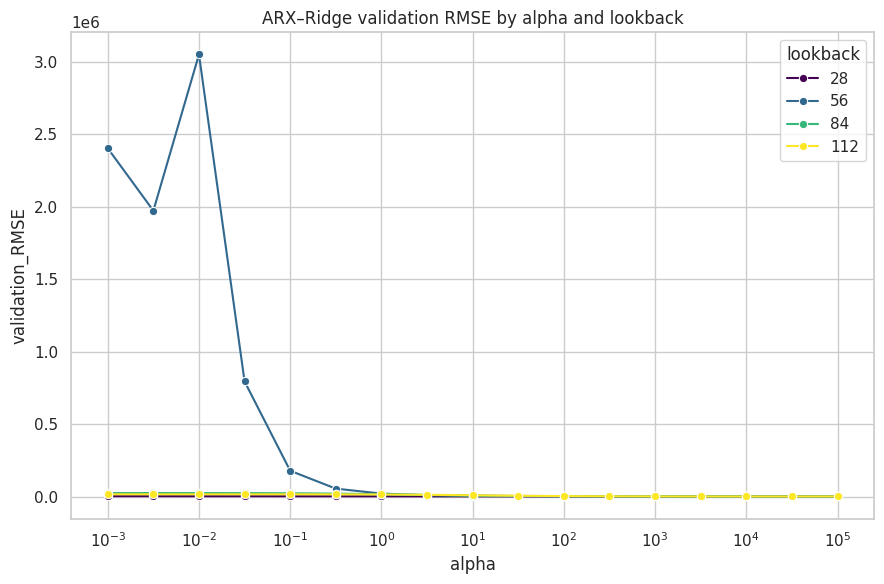

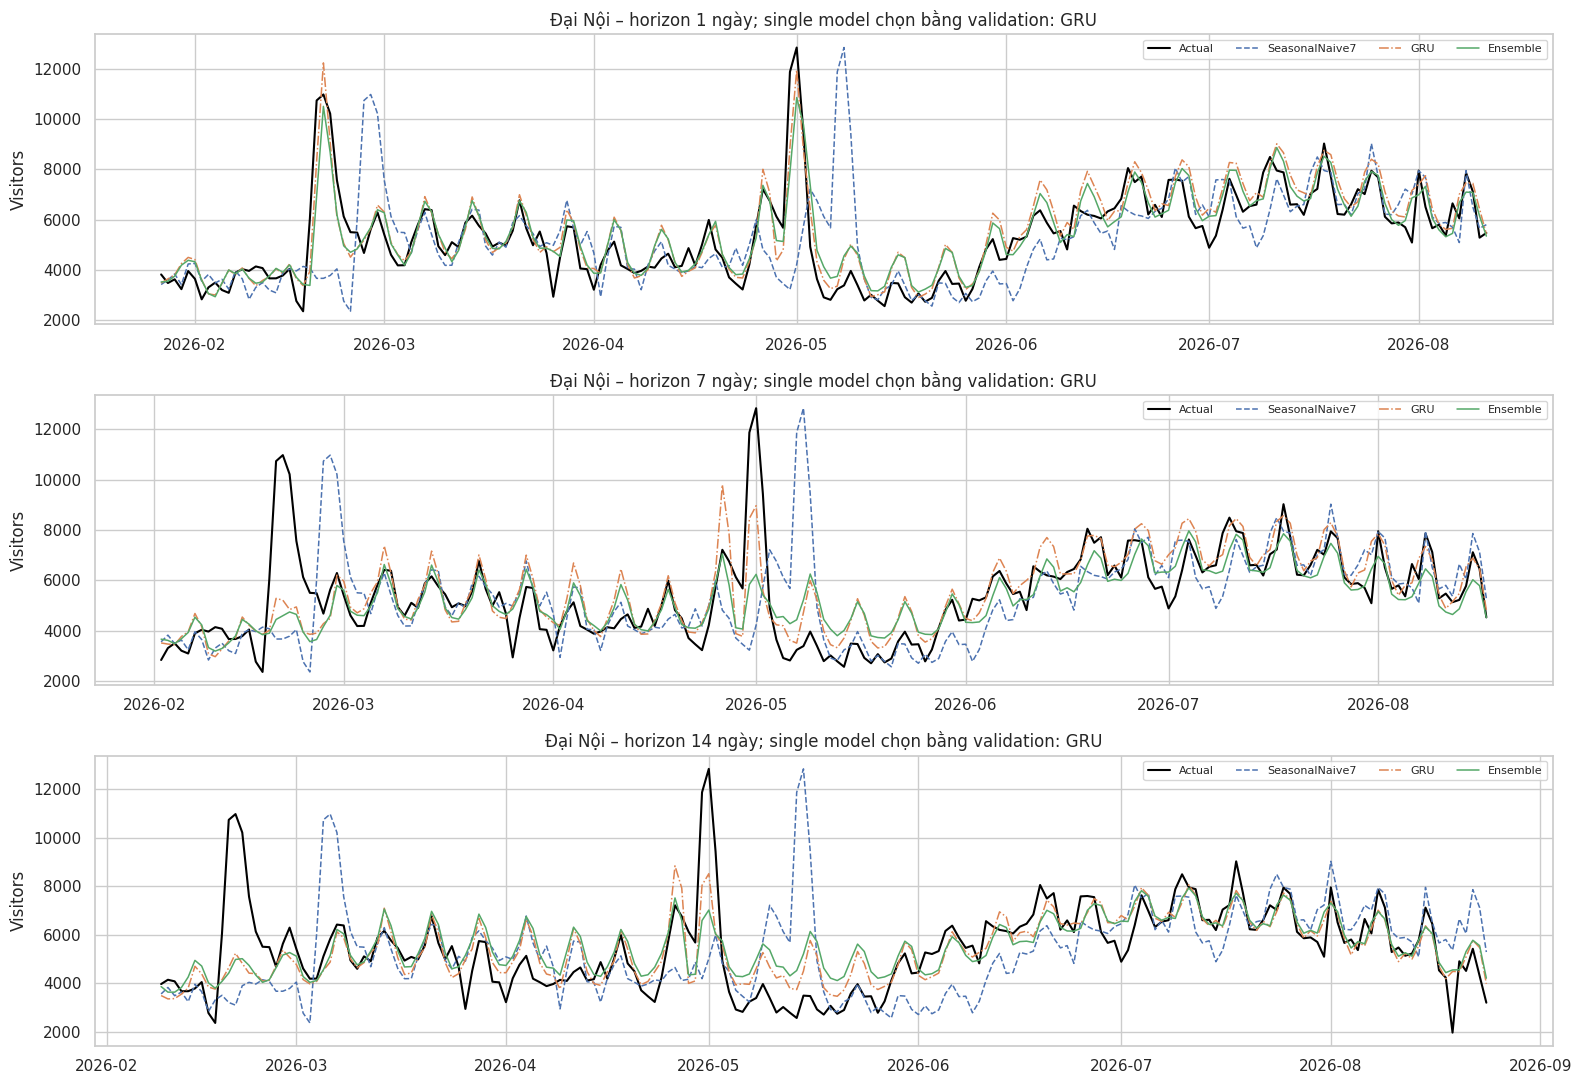

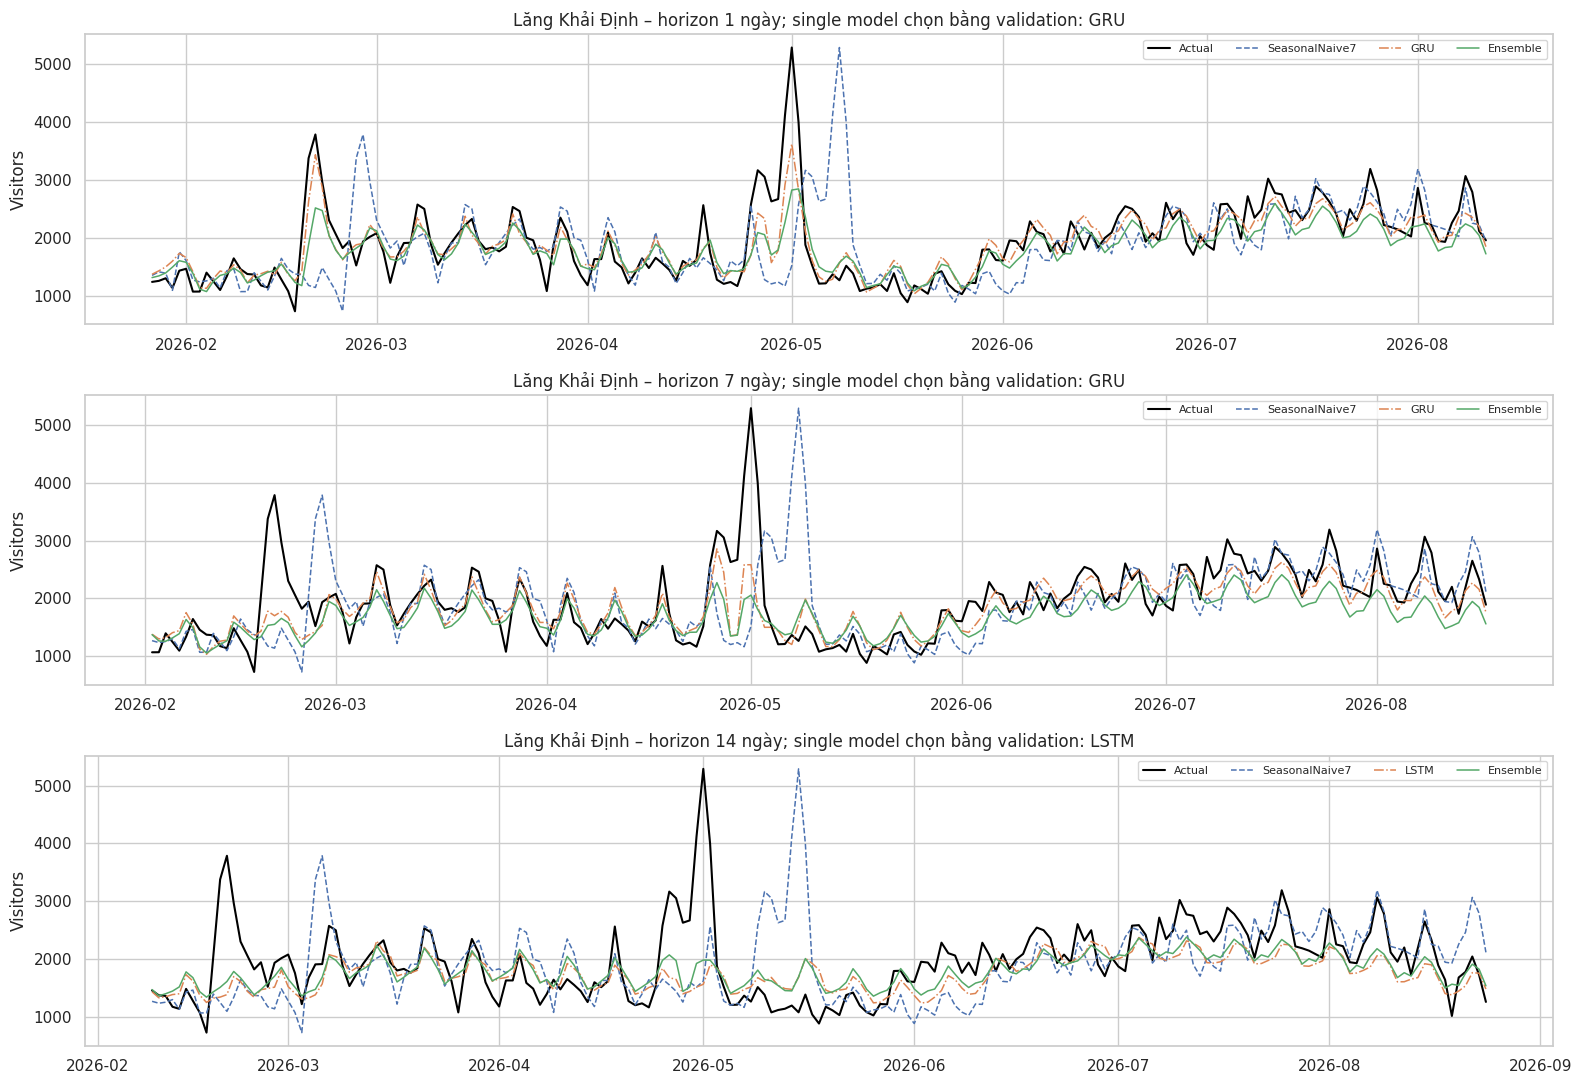

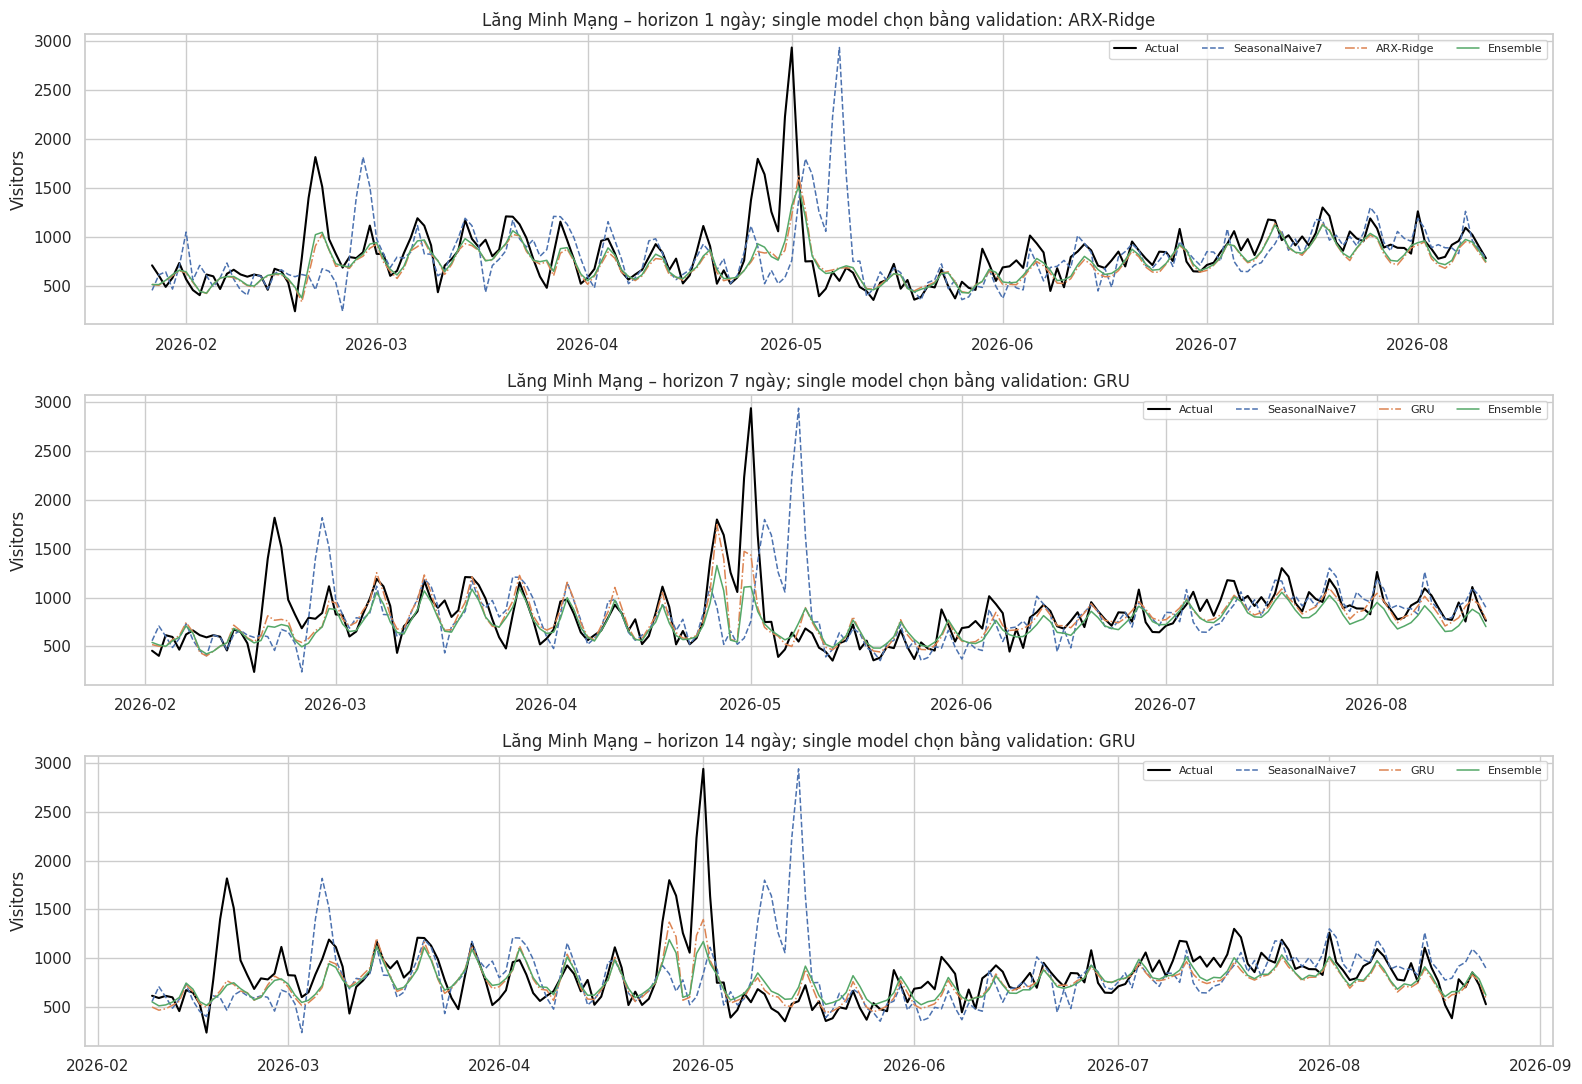

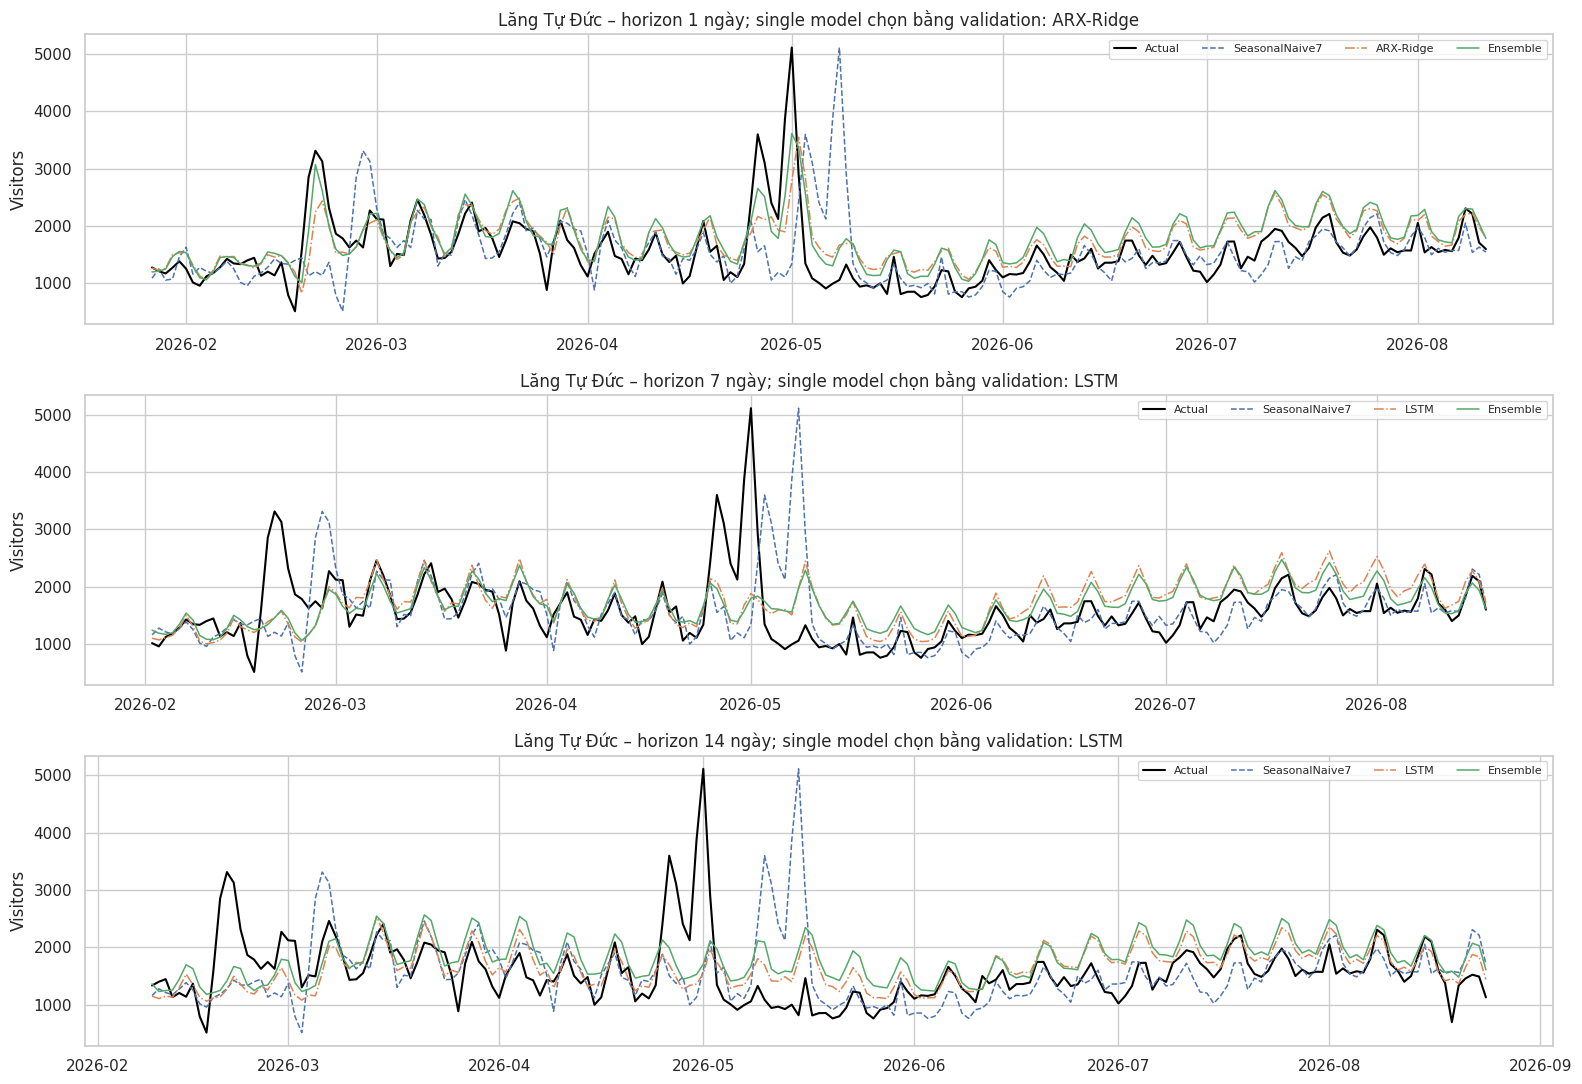

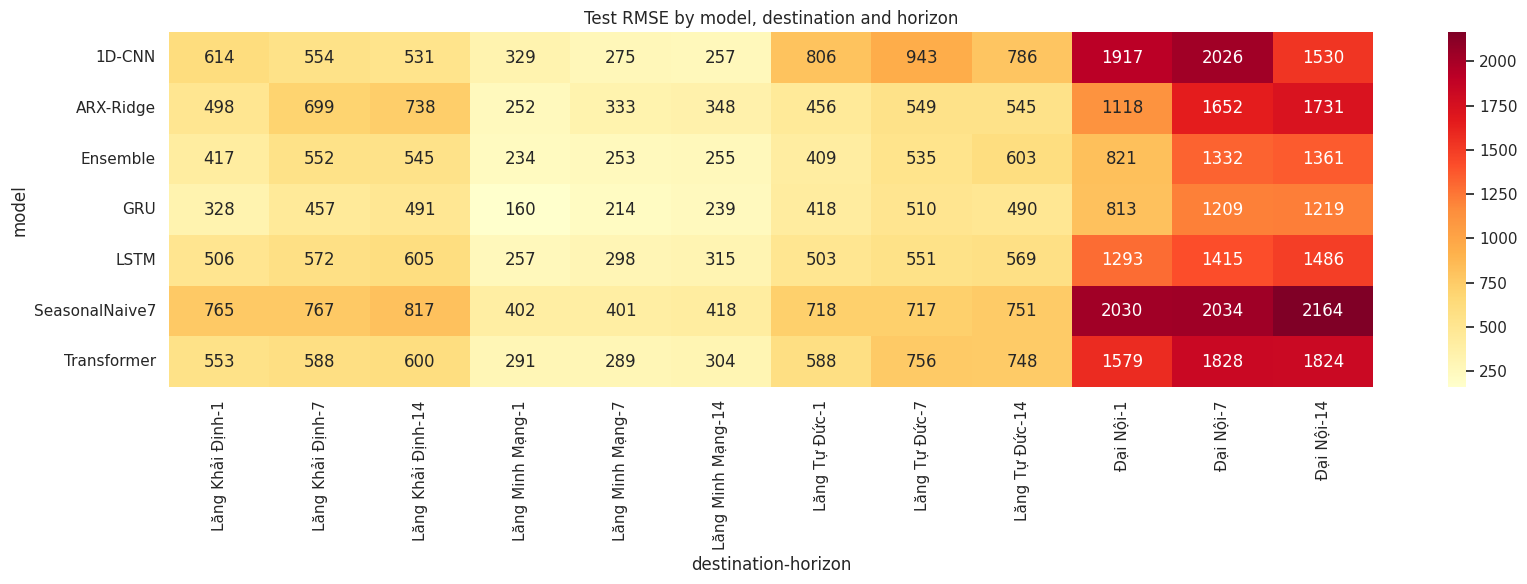

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, model_name in zip(axes.flat, DL_MODELS):
    hist = histories[model_name]
    ax.plot(np.arange(1, len(hist) + 1), hist['loss'], label='Train loss')
    ax.plot(np.arange(1, len(hist) + 1), hist['val_loss'], label='Validation loss')
    ax.axvline(best_epochs[model_name], color='crimson', ls='--', alpha=0.6, label='Best epoch')
    ax.set_title(model_name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Huber loss (scaled log1p target)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'deep_model_loss_curves.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(9, 6))
sns.lineplot(data=ridge_search_df, x='alpha', y='validation_RMSE', hue='lookback', marker='o', palette='viridis')
plt.xscale('log')
plt.title('ARX–Ridge validation RMSE by alpha and lookback')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'ridge_regularization_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Chọn mô hình đơn để vẽ chỉ bằng validation, không nhìn test.
val_op_metrics = metrics_by_site[
    metrics_by_site['split'].eq('validation') &
    metrics_by_site['scenario'].eq('operational_closure') &
    ~metrics_by_site['model'].isin(['SeasonalNaive7', 'Ensemble'])
]
best_single_by_pair = (val_op_metrics.sort_values('RMSE')
                       .groupby(['destination', 'horizon'], as_index=False).first())

for site_name in SITE_NAMES:
    fig, axes = plt.subplots(len(HORIZONS), 1, figsize=(16, 11), sharex=False)
    for ax, horizon in zip(axes, HORIZONS):
        pair = test_op[test_op['destination'].eq(site_name) & test_op['horizon'].eq(horizon)]
        actual = pair[pair['model'].eq('SeasonalNaive7')].sort_values('target_date')
        selected_model = best_single_by_pair[
            best_single_by_pair['destination'].eq(site_name) &
            best_single_by_pair['horizon'].eq(horizon)
        ]['model'].iloc[0]
        ax.plot(actual['target_date'], actual['actual'], color='black', lw=1.5, label='Actual')
        for model_name, style in [('SeasonalNaive7', '--'), (selected_model, '-.'), ('Ensemble', '-')]:
            part = pair[pair['model'].eq(model_name)].sort_values('target_date')
            ax.plot(part['target_date'], part['prediction'], ls=style, lw=1.1, label=model_name)
        ax.set_title(f'{site_name} – horizon {horizon} ngày; single model chọn bằng validation: {selected_model}')
        ax.set_ylabel('Visitors')
        ax.legend(ncol=4, fontsize=8)
    plt.tight_layout()
    safe_name = site_name.replace(' ', '_').replace('ă', 'a').replace('Đ', 'D')
    plt.savefig(FIGURE_DIR / f'test_forecast_{safe_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

rmse_heat = metrics_by_site[
    metrics_by_site['split'].eq('test') &
    metrics_by_site['scenario'].eq('operational_closure')
].pivot_table(index='model', columns=['destination', 'horizon'], values='RMSE')
plt.figure(figsize=(17, 6))
sns.heatmap(rmse_heat, annot=True, fmt='.0f', cmap='YlOrRd')
plt.title('Test RMSE by model, destination and horizon')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_rmse_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


## 15. Xuất Excel tổng hợp và manifest tái lập


In [15]:
# Excel dùng trực tiếp cho bảng bài báo.
excel_path = OUTPUT_ROOT / 'Hue_4_Destinations_Forecasting_Results.xlsx'
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    metrics_by_site.to_excel(writer, sheet_name='Metrics_by_site', index=False)
    metrics_aggregate.to_excel(writer, sheet_name='Metrics_aggregate', index=False)
    ensemble_weights_df.to_excel(writer, sheet_name='Ensemble_weights', index=False)
    dm_results.to_excel(writer, sheet_name='DM_tests', index=False)
    ridge_search_df.to_excel(writer, sheet_name='Ridge_search', index=False)
    audit_df.to_excel(writer, sheet_name='Data_audit', index=False)
    split_summary.to_excel(writer, sheet_name='Splits', index=False)
    zero_summary.to_excel(writer, sheet_name='Zero_days', index=False)

package_names = ['numpy', 'pandas', 'scikit-learn', 'scipy', 'statsmodels',
                 'tensorflow', 'optuna', 'holidays', 'gdown', 'openpyxl']
versions = {}
for package_name in package_names:
    try:
        versions[package_name] = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        versions[package_name] = 'not-found'

runtime_info = {
    'timestamp_utc': datetime.utcnow().isoformat() + 'Z',
    'python': platform.python_version(),
    'platform': platform.platform(),
    'tensorflow': tf.__version__,
    'gpu_devices': [str(x) for x in tf.config.list_physical_devices('GPU')],
    'packages': versions,
}
with open(LOG_DIR / 'environment_versions.json', 'w', encoding='utf-8') as handle:
    json.dump(runtime_info, handle, ensure_ascii=False, indent=2)

manifest = {
    'project': 'Hue four-destination daily visitor forecasting',
    'common_start': str(COMMON_START.date()),
    'horizons': HORIZONS,
    'lookback_candidates': LOOKBACK_CANDIDATES,
    'train_validation_test': split_summary.assign(
        start=split_summary['start'].astype(str), end=split_summary['end'].astype(str)
    ).to_dict('records'),
    'seed_for_tuning': SEED,
    'final_seeds': FINAL_SEEDS,
    'fast_mode': FAST_MODE,
    'run_optuna': RUN_OPTUNA,
    'trials_per_deep_model': N_TRIALS,
    'data_sha256': data_hashes,
    'best_ridge': best_ridge,
    'best_deep_hyperparameters': best_params,
    'best_epochs': best_epochs,
    'parameter_counts': parameter_counts,
    'confirmed_closure_dates': [str(x.date()) for x in sorted(CONFIRMED_CLOSURE_DATES)],
    'closure_override': APPLY_CONFIRMED_CLOSURE_OVERRIDE,
    'test_used_for_tuning': False,
}
with open(LOG_DIR / 'run_manifest.json', 'w', encoding='utf-8') as handle:
    json.dump(manifest, handle, ensure_ascii=False, indent=2, default=str)

print('Hoàn thành. Kết quả được lưu tại:', OUTPUT_ROOT)
print('Excel tổng hợp:', excel_path)
print('Mô hình có RMSE test trung bình thấp nhất theo horizon:')
display(test_summary.groupby('model', as_index=False)['RMSE'].mean().sort_values('RMSE'))


Hoàn thành. Kết quả được lưu tại: /content/drive/MyDrive/NCS/Tourist/2-results
Excel tổng hợp: /content/drive/MyDrive/NCS/Tourist/2-results/Hue_4_Destinations_Forecasting_Results.xlsx
Mô hình có RMSE test trung bình thấp nhất theo horizon:


,model,RMSE
3,GRU,635.535682
2,Ensemble,699.883613
4,LSTM,813.413916
1,ARX-Ridge,870.890722
6,Transformer,994.027781
0,1D-CNN,1055.103247
5,SeasonalNaive7,1185.391716


## Ghi chú diễn giải

1. Không chọn mô hình dựa vào test. Bảng test chỉ được đọc sau khi hoàn tất tuning và ensemble trên validation.
2. Không dùng MAPE làm chỉ số chính vì tồn tại ngày visitors bằng 0.
3. `operational_closure` chỉ hợp lệ khi ngày đóng cửa được xác nhận từ thông tin có sẵn tại thời điểm dự báo. Báo cáo đồng thời `model_only` để minh bạch.
4. Nếu bổ sung thời tiết/sự kiện, phải căn chỉnh theo thời điểm công bố và chỉ fit imputer/scaler trên train.
5. Khi viết bài, ưu tiên bảng MAE, RMSE, sMAPE, WAPE, MASE; dùng R² như chỉ số bổ sung và DM/Holm để so sánh thống kê.
